# 04 – WAR Model (v0.3)

**What changed from v0.2:** one thing.

| Change | Why |
|---|---|
| **`FINISH_WEIGHT` 0.5 → 0.3** | Finishing (goals minus expected goals) is the noisiest offensive stat. Scoring far above expected rarely repeats the next season. In v0.2, Cole Caufield ranked #2 largely because he scored 33 even-strength goals on 18 expected. Less reliable → less weight. |

Everything else is identical to v0.2, so any movement in the rankings comes from this one change. That's the point of changing one thing at a time.

Requires: notebooks 01–03 have been run.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA = Path("../data")
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

## 2. Load data
Same starting point as v0.1: the clean table from notebook 01, plus even-strength bench time and off-ice xG against from the raw file.

In [2]:
players = pd.read_csv(DATA / "skaters_clean.csv")
replacement_01 = pd.read_csv(DATA / "replacement_rates.csv", index_col=0)
raw = pd.read_csv(DATA / "skaters25-26.csv")

extra = (raw.loc[raw["situation"] == "5on5", ["playerId", "timeOnBench", "OffIce_A_xGoals"]]
            .rename(columns={"timeOnBench": "ev_bench_sec", "OffIce_A_xGoals": "ev_OffIce_A_xGoals"}))
players = players.merge(extra, on="playerId", how="left")
players["ev_bench_toi"] = players["ev_bench_sec"] / 60

print(players.shape)

(940, 76)


## 3. Model assumptions
Same as v0.2 except `FINISH_WEIGHT`.

| Constant | Value | Why |
|---|---|---|
| `GOALS_PER_WIN` | 6.0 | ~6 goals of goal differential ≈ 1 win |
| `PENALTY_GOAL_VALUE` | 0.17 | A power play is worth roughly 0.15–0.2 goals |
| `A1_WEIGHT` | 0.5 | Half credit for a primary assist |
| **`FINISH_WEIGHT`** | **0.3** | Finishing is real but noisy year to year (lowered from 0.5 in v0.2) |
| **`DEF_WEIGHT`** | 0.5 | On-ice defense is the least reliable measurement in the model, so it gets half weight |
| **`FO_GOAL_VALUE`** | 0.015 | A single faceoff win is worth roughly 0.01–0.02 goals on average |

In [3]:
GOALS_PER_WIN = 6.0
PENALTY_GOAL_VALUE = 0.17
A1_WEIGHT = 0.5
FINISH_WEIGHT = 0.3   # was 0.5 in v0.2
DEF_WEIGHT = 0.5
FO_GOAL_VALUE = 0.015

## 4. Helper functions
Three small functions used throughout, so the math is written once:
- `rate60`: per-60 rate, blank if no ice time
- `pooled`: total stat ÷ total minutes for a group (same pooling idea as notebook 01)
- `repl`: looks up the right replacement number for each player's position group

In [4]:
def rate60(count, toi):
    return np.where(toi > 0, count / toi * 60, np.nan)

def pooled(group, stat, toi_col):
    return group[stat].sum() / group[toi_col].sum() * 60

def repl(table, col):
    """Replacement value for each player's position group (F or D)."""
    return players["pos_group"].map(table[col])

## 5. Replacement levels
Each part of the game gets its own replacement pool:

| Situation | Regulars | Replacement pool |
|---|---|---|
| Even strength | Top 13 F / 7 D per team by ice time (from notebook 01) | Everyone else with 100+ EV minutes |
| Power play | Top 10 per team by PP time (two units) | Everyone else with 10+ PP minutes |
| Penalty kill | n/a | **League-average penalty killer** (see note) |
| Faceoffs | Regular centers | Non-regular centers with 100+ faceoffs |

**Even-strength defense** is the same as v0.1: team xG allowed per 60 on the **bench** minus on the **ice**.

**Penalty kill is handled differently**, because the v0.1 method broke here. When I first built this, elite penalty killers like Jaccob Slavin and Esa Lindell came out *below replacement level*. Two reasons:
1. **Bench comparison is unfair on the PK.** Top killers take the hardest shifts (start of the penalty, against the other team's best power play unit). When they're on the bench, it's often the easier tail end of the penalty.
2. **Fringe killers get easy minutes**, so the "replacement" group actually looked *better* than the regulars.

The fix: compare each player's on-ice PK xG against to **his team's overall PK rate**, and use the **league-average penalty killer** as the baseline instead of a replacement pool. This is a documented compromise.

In [5]:
# --- Even strength ---
players["ev_rel_xga_60"] = (rate60(players["ev_OffIce_A_xGoals"], players["ev_bench_toi"])
                            - rate60(players["ev_OnIce_A_xGoals"], players["ev_toi"]))
players["ev_rel_xga_60"] = players["ev_rel_xga_60"].fillna(0)

ev_pool = players[(~players["is_regular"]) & (players["ev_toi"] >= 100)]
ev_repl = replacement_01.copy()
ev_repl["fin_60"] = ev_repl["goals_60"] - ev_repl["ixg_60"]
ev_repl = ev_repl.join(ev_pool.groupby("pos_group").apply(lambda g: pd.Series({
    "rel_xga_60": (g["ev_rel_xga_60"] * g["ev_toi"]).sum() / g["ev_toi"].sum(),
    "pen_diff_60": g["pen_diff"].sum() / g["all_toi"].sum() * 60,
}), include_groups=False))

# --- Power play ---
players["pp_rank"] = players.groupby("team")["pp_toi"].rank(ascending=False, method="first")
pp_pool = players[(players["pp_rank"] > 10) & (players["pp_toi"] >= 10)]
pp_repl = pp_pool.groupby("pos_group").apply(lambda g: pd.Series({
    "ixg_60": pooled(g, "pp_I_F_xGoals", "pp_toi"),
    "fin_60": pooled(g, "pp_I_F_goals", "pp_toi") - pooled(g, "pp_I_F_xGoals", "pp_toi"),
    "a1_60":  pooled(g, "pp_I_F_primaryAssists", "pp_toi"),
}), include_groups=False)

# --- Penalty kill: team-relative, league-average baseline ---
team_pk_xga_60 = players.groupby("team").apply(
    lambda g: g["pk_OnIce_A_xGoals"].sum() / g["pk_toi"].sum() * 60, include_groups=False)
players["pk_rel_xga_60"] = (players["team"].map(team_pk_xga_60)
                            - rate60(players["pk_OnIce_A_xGoals"], players["pk_toi"]))
players["pk_rel_xga_60"] = players["pk_rel_xga_60"].fillna(0)
pk_pool = players[players["pk_toi"] >= 10]   # all penalty killers -> league average
pk_repl = pk_pool.groupby("pos_group").apply(lambda g: pd.Series({
    "rel_xga_60": (g["pk_rel_xga_60"] * g["pk_toi"]).sum() / g["pk_toi"].sum(),
}), include_groups=False)

# --- Faceoffs ---
players["fo_total"] = players["all_faceoffsWon"] + players["all_faceoffsLost"]
fo_pool = players[(players["position"] == "C") & (~players["is_regular"]) & (players["fo_total"] >= 100)]
FO_REPL_PCT = fo_pool["all_faceoffsWon"].sum() / fo_pool["fo_total"].sum()

print("Pool sizes  EV:", ev_pool.groupby("pos_group").size().to_dict(),
      "| PP:", pp_pool.groupby("pos_group").size().to_dict(),
      "| PK (all killers):", pk_pool.groupby("pos_group").size().to_dict(),
      "| FO centers:", len(fo_pool))
print(f"Replacement faceoff %: {FO_REPL_PCT:.3f}")
print()
print("Even strength replacement:"); print(ev_repl.round(3)); print()
print("Power play replacement:");    print(pp_repl.round(3)); print()
print("Penalty kill baseline (league average):");  print(pk_repl.round(3))

Pool sizes  EV: {'D': 46, 'F': 95} | PP: {'D': 48, 'F': 114} | PK (all killers): {'D': 224, 'F': 273} | FO centers: 22
Replacement faceoff %: 0.505

Even strength replacement:
           goals_60  a1_60  ixg_60  xgf_60  xga_60  fin_60  rel_xga_60  pen_diff_60
pos_group                                                                          
D             0.129  0.226   0.145   2.404   2.478  -0.016       0.007       -0.385
F             0.529  0.359   0.666   2.228   2.382  -0.136       0.120       -0.059

Power play replacement:
           ixg_60  fin_60  a1_60
pos_group                       
D           0.478  -0.156  1.217
F           1.403  -0.339  0.863

Penalty kill baseline (league average):
           rel_xga_60
pos_group            
D               0.007
F              -0.043


## 6. Offense: even strength + power play
Same formula for both situations:

`GAR = (xG − replacement xG) + 0.3 × (finishing − replacement finishing) + 0.5 × (primary assists − replacement A1)`

where **finishing = goals − expected goals**, and every replacement number is scaled to the player's own minutes.

In [6]:
def offense_gar(prefix, repl_table):
    hours = players[f"{prefix}_toi"] / 60
    xg, goals, a1 = (players[f"{prefix}_I_F_xGoals"], players[f"{prefix}_I_F_goals"],
                     players[f"{prefix}_I_F_primaryAssists"])
    return ((xg - repl(repl_table, "ixg_60") * hours)
            + FINISH_WEIGHT * ((goals - xg) - repl(repl_table, "fin_60") * hours)
            + A1_WEIGHT * (a1 - repl(repl_table, "a1_60") * hours))

players["ev_off_gar"] = offense_gar("ev", ev_repl)
players["pp_off_gar"] = offense_gar("pp", pp_repl)

players.sort_values("pp_off_gar", ascending=False)[["name", "team", "pp_toi", "pp_I_F_goals", "pp_off_gar"]].head(10).round(2)

,name,team,pp_toi,pp_I_F_goals,pp_off_gar
862,Connor McDavid,EDM,283.03,12.0,14.45
136,Wyatt Johnston,DAL,273.23,23.0,13.15
596,Leon Draisaitl,EDM,225.42,16.0,12.57
227,Jake DeBrusk,VAN,231.00,19.0,11.87
857,Mika Zibanejad,NYR,252.53,16.0,10.93
737,Pavel Dorofeyev,VGK,269.70,19.0,10.45
433,Sam Reinhart,FLA,254.45,10.0,10.11
658,Mark Stone,VGK,197.32,9.0,9.69
930,David Pastrnak,BOS,265.45,7.0,8.29
933,Cole Caufield,MTL,259.35,10.0,8.23


## 7. Defense: even strength + penalty kill (half weight)

In [7]:
players["ev_def_gar"] = DEF_WEIGHT * (players["ev_rel_xga_60"] - repl(ev_repl, "rel_xga_60")) * players["ev_toi"] / 60
players["pk_def_gar"] = DEF_WEIGHT * (players["pk_rel_xga_60"] - repl(pk_repl, "rel_xga_60")) * players["pk_toi"] / 60

players.sort_values("pk_def_gar", ascending=False)[["name", "team", "position", "pk_toi", "pk_def_gar"]].head(10).round(2)

,name,team,position,pk_toi,pk_def_gar
813,Connor Murphy,EDM,D,208.97,2.97
774,Jason Dickinson,EDM,C,129.45,2.86
187,Brock Nelson,COL,C,140.55,2.64
99,Noah Cates,PHI,L,135.17,2.43
898,Collin Graf,SJS,R,195.55,2.42
862,Connor McDavid,EDM,C,83.30,2.07
901,Noah Dobson,MTL,D,155.57,2.05
345,Ilya Mikheyev,CHI,R,190.47,2.04
799,Vincent Desharnais,SJS,D,165.52,1.98
776,Erik Karlsson,PIT,D,136.65,1.94


## 8. Penalties and faceoffs

In [8]:
players["pen_gar"] = PENALTY_GOAL_VALUE * (players["pen_diff"] - repl(ev_repl, "pen_diff_60") * players["all_toi"] / 60)

players["fo_gar"] = np.where(players["position"] == "C",
                             FO_GOAL_VALUE * (players["all_faceoffsWon"] - FO_REPL_PCT * players["fo_total"]),
                             0.0)

players.sort_values("fo_gar", ascending=False)[["name", "team", "fo_total", "fo_pct", "fo_gar"]].head(5).round(3)

,name,team,fo_total,fo_pct,fo_gar
508,Jonathan Toews,WPG,1026.0,0.621,1.790
619,Dylan Strome,WSH,1334.0,0.582,1.558
649,John Tavares,TOR,1392.0,0.575,1.479
198,J.T. Miller,NYR,890.0,0.615,1.469
431,Nico Hischier,NJD,1808.0,0.558,1.436


## 9. Total WAR and leaderboard

In [9]:
COMPONENTS = ["ev_off_gar", "pp_off_gar", "ev_def_gar", "pk_def_gar", "pen_gar", "fo_gar"]

players["gar"] = players[COMPONENTS].sum(axis=1)
players["war"] = players["gar"] / GOALS_PER_WIN
players["war_rank"] = players["war"].rank(ascending=False, method="min").astype(int)

leaders = (players.sort_values("war", ascending=False)
                  [["name", "team", "position"] + COMPONENTS + ["war"]]
                  .head(20).reset_index(drop=True))
leaders.index = leaders.index + 1
leaders.round(2)

,name,team,position,ev_off_gar,pp_off_gar,ev_def_gar,pk_def_gar,pen_gar,fo_gar,war
1,Connor McDavid,EDM,C,13.19,14.45,-4.51,2.07,5.58,-0.13,5.11
2,Cole Caufield,MTL,R,13.01,8.23,0.88,0.03,1.77,0.00,3.99
3,David Pastrnak,BOS,R,14.73,8.29,-1.60,0.14,1.28,0.00,3.81
4,Nathan MacKinnon,COL,C,20.37,6.48,-6.36,0.14,1.49,0.12,3.71
5,Leon Draisaitl,EDM,C,7.81,12.57,-0.89,1.18,-0.11,1.07,3.61
6,Mark Stone,VGK,R,6.75,9.69,0.85,0.62,2.40,0.00,3.38
7,Rasmus Dahlin,BUF,D,12.18,2.41,2.92,0.98,0.67,0.00,3.19
8,Mika Zibanejad,NYR,C,5.63,10.93,0.87,0.72,0.62,0.33,3.18
9,Lane Hutson,MTL,D,10.22,-0.75,5.79,0.42,2.98,0.00,3.11
10,Cale Makar,COL,D,12.37,4.56,-3.16,0.78,3.90,0.00,3.07


In [10]:
for grp, label in [("F", "Forwards"), ("D", "Defensemen")]:
    print(label)
    print(players[players["pos_group"] == grp]
          .sort_values("war", ascending=False)[["name", "team", "war"]]
          .head(5).round(2).to_string(index=False))
    print()
print("Defensemen in the top 20:", (players.nsmallest(20, "war_rank")["pos_group"] == "D").sum())

Forwards
            name team  war
  Connor McDavid  EDM 5.11
   Cole Caufield  MTL 3.99
  David Pastrnak  BOS 3.81
Nathan MacKinnon  COL 3.71
  Leon Draisaitl  EDM 3.61

Defensemen
         name team  war
Rasmus Dahlin  BUF 3.19
  Lane Hutson  MTL 3.11
   Cale Makar  COL 3.07
Zach Werenski  CBJ 2.87
Evan Bouchard  EDM 2.67

Defensemen in the top 20: 5


## 10. Chart: what drives the top 15 (v0.3)

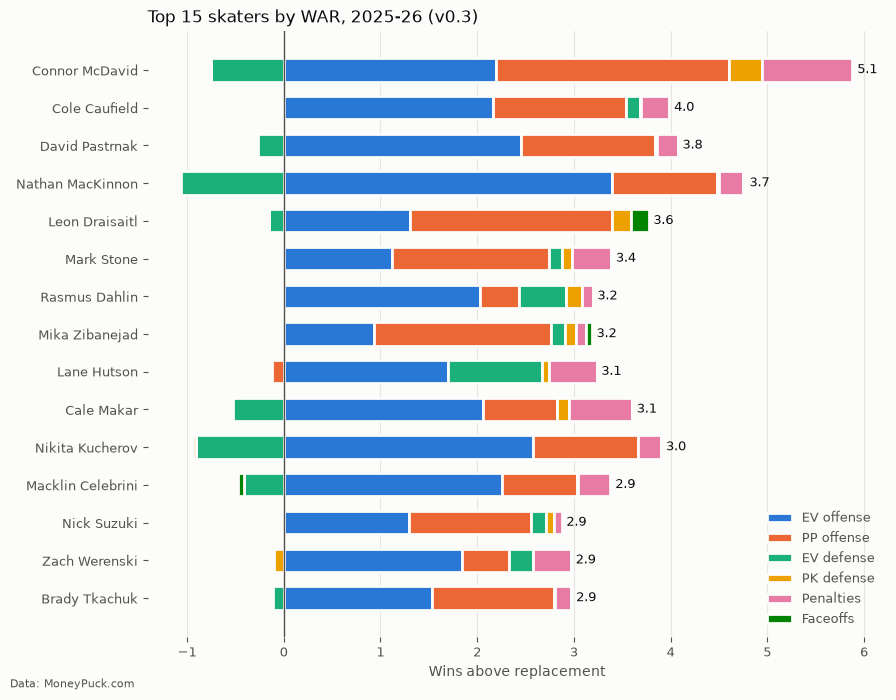

In [11]:
COLORS = {"ev_off_gar": "#2a78d6", "pp_off_gar": "#eb6834", "ev_def_gar": "#1baf7a",
          "pk_def_gar": "#eda100", "pen_gar": "#e87ba4", "fo_gar": "#008300"}
LABELS = {"ev_off_gar": "EV offense", "pp_off_gar": "PP offense", "ev_def_gar": "EV defense",
          "pk_def_gar": "PK defense", "pen_gar": "Penalties", "fo_gar": "Faceoffs"}
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"

def component_chart(df, title, path):
    top = df.sort_values("war", ascending=False).head(15).iloc[::-1]
    comp = top[list(COLORS)] / GOALS_PER_WIN
    fig, ax = plt.subplots(figsize=(9, 7), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    pos_left, neg_left = np.zeros(len(top)), np.zeros(len(top))
    for col, color in COLORS.items():
        vals = comp[col].to_numpy()
        ax.barh(top["name"], vals, left=np.where(vals >= 0, pos_left, neg_left), color=color,
                height=0.62, edgecolor=SURFACE, linewidth=2, label=LABELS[col])
        pos_left += np.where(vals >= 0, vals, 0)
        neg_left += np.where(vals < 0, vals, 0)
    for y, (total, end) in enumerate(zip(top["war"], pos_left)):
        ax.text(end + 0.05, y, f"{total:.1f}", va="center", fontsize=9, color=INK)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_xlabel("Wins above replacement", color=MUTED)
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=MUTED)
    fig.text(0.01, 0.01, "Data: MoneyPuck.com", fontsize=8, color=MUTED)
    plt.tight_layout()
    fig.savefig(path, dpi=150, facecolor=SURFACE)
    plt.show()

component_chart(players, "Top 15 skaters by WAR, 2025-26 (v0.3)", IMAGES / "war_top15_v03.png")

## 11. Version comparison: v0.2 vs v0.3
Same approach as notebook 03, now using `war_history.csv`, which holds every version so far. This notebook adds the v0.3 columns to it.

In [12]:
history = pd.read_csv(DATA / "war_history.csv")
v03 = players[["playerId", "war"]].rename(columns={"war": "war_v03"})
history = history.drop(columns=["war_v03", "rank_v03"], errors="ignore").merge(v03, on="playerId", how="left")
history["rank_v03"] = history["war_v03"].rank(ascending=False, method="min").astype(int)
history["change_v02_v03"] = history["rank_v02"] - history["rank_v03"]   # positive = moved up

corr = history["war_v02"].corr(history["war_v03"], method="spearman")
print(f"Spearman rank correlation, v0.2 vs v0.3: {corr:.2f}")

regulars = history[history["ev_toi"] >= 500]
show = ["name", "team", "position", "rank_v01", "rank_v02", "rank_v03", "change_v02_v03", "war_v02", "war_v03"]
print("\nBiggest risers (500+ EV minutes):")
print(regulars.sort_values("change_v02_v03", ascending=False)[show].head(8).round(2).to_string(index=False))
print("\nBiggest fallers (500+ EV minutes):")
print(regulars.sort_values("change_v02_v03")[show].head(8).round(2).to_string(index=False))

Spearman rank correlation, v0.2 vs v0.3: 0.99

Biggest risers (500+ EV minutes):
              name team position  rank_v01  rank_v02  rank_v03  change_v02_v03  war_v02  war_v03
    Trent Frederic  EDM        C       268       731       547             184    -0.12     0.02
        Adam Lowry  WPG        C       365       645       474             171    -0.03     0.09
     Alex Turcotte  LAK        C       348       526       355             171     0.04     0.29
      Yakov Trenin  MIN        C       402       555       409             146     0.02     0.19
       Adam Wilsby  NSH        D       350       709       567             142    -0.10     0.01
Rasmus Ristolainen  PHI        D       628       619       491             128    -0.02     0.07
 Brendan Gallagher  MTL        R       646       824       697             127    -0.27    -0.09
     Dylan Samberg  WPG        D       133       698       580             118    -0.08     0.00

Biggest fallers (500+ EV minutes):
          

### Rank change chart
For the v0.3 top 15: gray = v0.2 rank, blue = v0.3 rank.

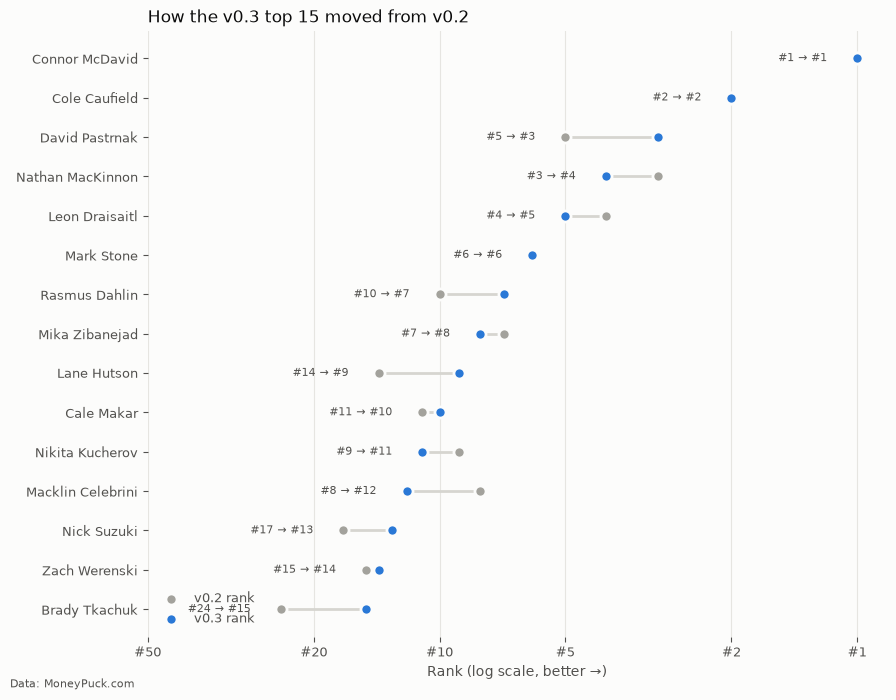

In [13]:
top = history.sort_values("rank_v03").head(15).iloc[::-1]
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(9, 7), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.hlines(y, top["rank_v03"], top["rank_v02"], color="#d6d5d0", linewidth=2, zorder=1)
ax.scatter(top["rank_v02"], y, s=64, color="#a3a29c", edgecolor=SURFACE, linewidth=2, zorder=2, label="v0.2 rank")
ax.scatter(top["rank_v03"], y, s=64, color="#2a78d6", edgecolor=SURFACE, linewidth=2, zorder=3, label="v0.3 rank")
for yi, (r1, r2) in enumerate(zip(top["rank_v02"], top["rank_v03"])):
    ax.text(max(r1, r2) * 1.18, yi, f"#{r1} → #{r2}", va="center", ha="right", fontsize=8, color=MUTED)

ax.set_yticks(y)
ax.set_yticklabels(top["name"])
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_xticks([1, 2, 5, 10, 20, 50])
ax.set_xticklabels(["#1", "#2", "#5", "#10", "#20", "#50"])
ax.minorticks_off()
ax.set_xlabel("Rank (log scale, better →)", color=MUTED)
ax.set_title("How the v0.3 top 15 moved from v0.2", loc="left", color=INK, fontsize=12)
ax.tick_params(colors=MUTED, labelsize=9)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor=MUTED)
fig.text(0.01, 0.01, "Data: MoneyPuck.com", fontsize=8, color=MUTED)
plt.tight_layout()
fig.savefig(IMAGES / "rank_change_v02_v03.png", dpi=150, facecolor=SURFACE)
plt.show()

## 12. Model history: the superstars across all versions

In [14]:
STARS = ["Connor McDavid", "Nathan MacKinnon", "Nikita Kucherov", "Leon Draisaitl", "Cole Caufield",
         "Auston Matthews", "Cale Makar", "Quinn Hughes", "David Pastrnak", "Lane Hutson"]

(history[history["name"].isin(STARS)]
    [["name", "team", "rank_v01", "rank_v02", "rank_v03", "war_v01", "war_v02", "war_v03"]]
    .sort_values("rank_v03").round(2))

,name,team,rank_v01,rank_v02,rank_v03,war_v01,war_v02,war_v03
862,Connor McDavid,EDM,55,1,1,1.30,5.40,5.11
933,Cole Caufield,MTL,15,2,2,1.88,4.63,3.99
930,David Pastrnak,BOS,14,5,3,1.94,3.97,3.81
547,Nathan MacKinnon,COL,116,3,4,0.87,4.21,3.71
596,Leon Draisaitl,EDM,171,4,5,0.62,4.10,3.61
462,Lane Hutson,MTL,1,14,9,4.09,3.17,3.11
822,Cale Makar,COL,47,11,10,1.36,3.22,3.07
65,Nikita Kucherov,TBL,256,9,11,0.38,3.41,2.96
417,Quinn Hughes,MIN,13,40,28,1.96,2.42,2.44
834,Auston Matthews,TOR,162,63,57,0.64,1.97,1.88


**Question for you:** where did Caufield land in v0.3? Did one change fix the problem, or is something else still inflating him? Who rose the most from this change, and why does that make sense?

## 13. Save

In [15]:
players.to_csv(DATA / "war_v03.csv", index=False)
history.to_csv(DATA / "war_history.csv", index=False)
print("Saved war_v03.csv and updated war_history.csv with v0.3 columns")

Saved war_v03.csv and updated war_history.csv with v0.3 columns


## Known limitations (v0.3)
- **Defense is still the weakest piece**: half weight reduces the noise but doesn't remove the competition and linemate effects
- **Shutdown defensemen are undervalued**: low offense plus half-weight defense pushes players like Slavin and Forsling toward replacement level. Public models struggle with this too, but it's a real gap
- **Penalty kill uses a league-average baseline**, not replacement, so PK value is slightly understated
- **No adjustment for quality of competition or zone starts**
- **Constants are approximations** (goals per win, penalty value, faceoff value, assist and finishing weights)
- **Goalies are not included**
- **Traded players** are listed under one team

## Next
- Compare the leaderboard to a public WAR model
- Start on the roadmap: **aging curves**